In [1]:
import os, numpy as np, pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [2]:
SEED = 42
CLASSES = ["Normal", "Bleeding", "Ischemia"]
base = "/kaggle/input/datasets/ozguraslank/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset"
kb = "/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage"

In [3]:
# Main data: same file order and seed as our first run, so the splits are identical
rows = []
for cls in CLASSES:
    for f in sorted(os.listdir(f"{base}/{cls}/PNG")):
        rows.append({"id": f[:-4], "cls": cls, "png": f"{base}/{cls}/PNG/{f}"})
df = pd.DataFrame(rows)
df["bleed"] = (df["cls"] == "Bleeding").astype(int)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["cls"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["cls"], random_state=SEED)

# Same-source held-out set: label is "any stroke"
ext = pd.read_csv(f"{base}/External_Test/labels.csv")
ext["png"] = [f"{base}/External_Test/PNG/{i}.png" for i in ext["image_id"]]
ext["stroke"] = ext["Stroke"].astype(int)

# Different-source set (Kitamura), split in two halves:
#   DEV   = used to compare experiments and choose settings
#   FINAL = looked at once, at the very end
kl = pd.read_csv(f"{kb}/labels.csv"); kl.columns = [c.strip() for c in kl.columns]
lab = kl.columns[1]
def kpath(i):
    s = str(i)
    return f"{kb}/head_ct/head_ct/{s}" if s.endswith(".png") else f"{kb}/head_ct/head_ct/{int(i):03d}.png"
kdf = pd.DataFrame({"png": [kpath(i) for i in kl.iloc[:, 0]], "bleed": kl[lab].astype(int).values})
kdev, kfin = train_test_split(kdf, test_size=0.5, stratify=kdf["bleed"], random_state=SEED)
print("train/val/test:", len(train_df), len(val_df), len(test_df), "| ExtTest:", len(ext), "| Kitamura dev/final:", len(kdev), len(kfin))
print("Kitamura dev:", kdev["bleed"].value_counts().to_dict(), "| final:", kfin["bleed"].value_counts().to_dict())

def rec_fa(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((y == 1) & (pred == 1)).sum()); fn = int(((y == 1) & (pred == 0)).sum())
    fp = int(((y == 0) & (pred == 1)).sum()); neg = int((y == 0).sum())
    return tp / (tp + fn), fp / neg, fn, fp

LOG, STORE = [], {}
def evaluate_all(name, model, tf_ev, thr=0.5):
    P_val = probs(model, val_df["png"].tolist(), tf_ev)
    P_ext = probs(model, ext["png"].tolist(), tf_ev)
    P_kd = probs(model, kdev["png"].tolist(), tf_ev)
    STORE[name] = {"val": P_val, "ext": P_ext, "kdev": P_kd}
    r1, f1, _, _ = rec_fa(val_df["bleed"], P_val[:, 1] >= thr)
    r2, f2, _, _ = rec_fa(ext["stroke"], (1 - P_ext[:, 0]) >= thr)
    r3, f3, _, _ = rec_fa(kdev["bleed"], P_kd[:, 1] >= thr)
    LOG.append({"experiment": name,
        "val bleed recall": round(r1, 3), "val false-alarm rate": round(f1, 3),
        "val AUC": round(roc_auc_score(val_df["bleed"], P_val[:, 1]), 3),
        "ExtTest stroke recall": round(r2, 3), "ExtTest false-alarm rate": round(f2, 3),
        "KitDev bleed recall": round(r3, 3), "KitDev false-alarm rate": round(f3, 3),
        "KitDev AUC": round(roc_auc_score(kdev["bleed"], P_kd[:, 1]), 3)})
    log = pd.DataFrame(LOG)
    log.to_csv("/kaggle/working/experiment_log.csv", index=False)
    return log.set_index("experiment").T

train/val/test: 4655 997 998 | ExtTest: 200 | Kitamura dev/final: 100 100
Kitamura dev: {0: 50, 1: 50} | final: {1: 50, 0: 50}


In [4]:
import torch, torch.nn as nn, torchvision
from PIL import ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

In [6]:
def autocontrast(im):
    return ImageOps.autocontrast(im, cutoff=1)

def make_tf(train, aug=False, auto=False):
    steps = [T.Lambda(autocontrast)] if auto else []
    if train and aug:
        steps += [T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomRotation(10),
                  T.ColorJitter(brightness=0.3, contrast=0.3)]
    else:
        steps += [T.Resize((224, 224))]
    return T.Compose(steps + [T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, paths, labels, tf):
        self.p, self.y, self.tf = list(paths), list(labels), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def probs(model, paths, tf_ev):
    dl = DataLoader(DS(paths, [0] * len(paths), tf_ev), batch_size=64, shuffle=False, num_workers=2)
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in dl:
            out.append(model(xb.to(device)).softmax(1).cpu().numpy())
    return np.concatenate(out)

def train_model(name, arch="resnet18", epochs=6, aug=False, auto=False, lr=3e-4):
    torch.manual_seed(SEED); np.random.seed(SEED)
    tf_tr, tf_ev = make_tf(True, aug, auto), make_tf(False, aug, auto)
    tr_dl = DataLoader(DS(train_df["png"], [CLASSES.index(c) for c in train_df["cls"]], tf_tr),
                       batch_size=64, shuffle=True, num_workers=2)
    model = getattr(torchvision.models, arch)(weights="DEFAULT")
    model.fc = nn.Linear(model.fc.in_features, 3)
    model = model.to(device)
    counts = train_df["cls"].value_counts()
    w = torch.tensor([len(train_df) / (3 * counts[c]) for c in CLASSES], dtype=torch.float32).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_auc, best_state = 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            opt.zero_grad()
            loss_fn(model(xb.to(device)), yb.to(device)).backward()
            opt.step()
        auc = roc_auc_score(val_df["bleed"], probs(model, val_df["png"].tolist(), tf_ev)[:, 1])
        print(f"{name} epoch {epoch + 1}: validation bleed AUC {auc:.3f}")
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, f"/kaggle/working/{name}.pt")
    return model, tf_ev

In [7]:
# E0: the model we already had (no augmentation), re-run so it is logged the same way
model, tf_ev = train_model("E0_plain", epochs=5)
evaluate_all("E0_plain", model, tf_ev)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s] 


E0_plain epoch 1: validation bleed AUC 0.986
E0_plain epoch 2: validation bleed AUC 0.995
E0_plain epoch 3: validation bleed AUC 0.972
E0_plain epoch 4: validation bleed AUC 0.995
E0_plain epoch 5: validation bleed AUC 0.992


experiment,E0_plain
val bleed recall,0.927
val false-alarm rate,0.010
val AUC,0.995
ExtTest stroke recall,0.843
ExtTest false-alarm rate,0.092
KitDev bleed recall,0.920
KitDev false-alarm rate,0.160
KitDev AUC,0.945


In [8]:
# E1: add augmentation (random crop, small rotation, brightness/contrast changes)
model, tf_ev = train_model("E1_aug", epochs=8, aug=True)
evaluate_all("E1_aug", model, tf_ev)

E1_aug epoch 1: validation bleed AUC 0.980
E1_aug epoch 2: validation bleed AUC 0.978
E1_aug epoch 3: validation bleed AUC 0.979
E1_aug epoch 4: validation bleed AUC 0.990
E1_aug epoch 5: validation bleed AUC 0.981
E1_aug epoch 6: validation bleed AUC 0.988
E1_aug epoch 7: validation bleed AUC 0.991
E1_aug epoch 8: validation bleed AUC 0.989


experiment,E0_plain,E1_aug
val bleed recall,0.927,0.890
val false-alarm rate,0.010,0.007
val AUC,0.995,0.991
ExtTest stroke recall,0.843,0.843
ExtTest false-alarm rate,0.092,0.069
KitDev bleed recall,0.920,1.000
KitDev false-alarm rate,0.160,0.180
KitDev AUC,0.945,0.992


In [9]:
# E2: augmentation + per-image contrast stretching to reduce scanner/brightness differences
model, tf_ev = train_model("E2_aug_autocontrast", epochs=8, aug=True, auto=True)
evaluate_all("E2_aug_autocontrast", model, tf_ev)

E2_aug_autocontrast epoch 1: validation bleed AUC 0.982
E2_aug_autocontrast epoch 2: validation bleed AUC 0.973
E2_aug_autocontrast epoch 3: validation bleed AUC 0.986
E2_aug_autocontrast epoch 4: validation bleed AUC 0.981
E2_aug_autocontrast epoch 5: validation bleed AUC 0.981
E2_aug_autocontrast epoch 6: validation bleed AUC 0.990
E2_aug_autocontrast epoch 7: validation bleed AUC 0.989
E2_aug_autocontrast epoch 8: validation bleed AUC 0.994


experiment,E0_plain,E1_aug,E2_aug_autocontrast
val bleed recall,0.927,0.890,0.945
val false-alarm rate,0.010,0.007,0.012
val AUC,0.995,0.991,0.994
ExtTest stroke recall,0.843,0.843,0.957
ExtTest false-alarm rate,0.092,0.069,0.362
KitDev bleed recall,0.920,1.000,0.940
KitDev false-alarm rate,0.160,0.180,0.140
KitDev AUC,0.945,0.992,0.972


In [10]:
def run(config, seed, **kw):
    global SEED
    SEED = seed
    name = f"{config}_s{seed}"
    model, tf_ev = train_model(name, **kw)
    return evaluate_all(name, model, tf_ev)

def seed_summary():
    log = pd.DataFrame(LOG)
    m = log["experiment"].str.extract(r"^(.*)_s(\d+)$")
    log["config"] = m[0]
    seeds = log.dropna(subset=["config"])
    cols = [c for c in log.columns if c not in ("experiment", "config")]
    fmt = lambda s: f"{s.mean():.3f} ({s.min():.3f}-{s.max():.3f})"
    return seeds.groupby("config")[cols].agg(fmt).T

In [11]:
for s in [1, 2, 3]:
    run("E0_plain", s, epochs=5)

E0_plain_s1 epoch 1: validation bleed AUC 0.986
E0_plain_s1 epoch 2: validation bleed AUC 0.989
E0_plain_s1 epoch 3: validation bleed AUC 0.994
E0_plain_s1 epoch 4: validation bleed AUC 0.993
E0_plain_s1 epoch 5: validation bleed AUC 0.994
E0_plain_s2 epoch 1: validation bleed AUC 0.975
E0_plain_s2 epoch 2: validation bleed AUC 0.988
E0_plain_s2 epoch 3: validation bleed AUC 0.994
E0_plain_s2 epoch 4: validation bleed AUC 0.992
E0_plain_s2 epoch 5: validation bleed AUC 0.995
E0_plain_s3 epoch 1: validation bleed AUC 0.980
E0_plain_s3 epoch 2: validation bleed AUC 0.972
E0_plain_s3 epoch 3: validation bleed AUC 0.994
E0_plain_s3 epoch 4: validation bleed AUC 0.993
E0_plain_s3 epoch 5: validation bleed AUC 0.996


In [12]:
for s in [1, 2, 3]:
    run("E1_aug", s, epochs=8, aug=True)

E1_aug_s1 epoch 1: validation bleed AUC 0.969
E1_aug_s1 epoch 2: validation bleed AUC 0.966
E1_aug_s1 epoch 3: validation bleed AUC 0.992
E1_aug_s1 epoch 4: validation bleed AUC 0.990
E1_aug_s1 epoch 5: validation bleed AUC 0.984
E1_aug_s1 epoch 6: validation bleed AUC 0.985
E1_aug_s1 epoch 7: validation bleed AUC 0.989
E1_aug_s1 epoch 8: validation bleed AUC 0.991
E1_aug_s2 epoch 1: validation bleed AUC 0.968
E1_aug_s2 epoch 2: validation bleed AUC 0.983
E1_aug_s2 epoch 3: validation bleed AUC 0.984
E1_aug_s2 epoch 4: validation bleed AUC 0.985
E1_aug_s2 epoch 5: validation bleed AUC 0.987
E1_aug_s2 epoch 6: validation bleed AUC 0.987
E1_aug_s2 epoch 7: validation bleed AUC 0.985
E1_aug_s2 epoch 8: validation bleed AUC 0.990
E1_aug_s3 epoch 1: validation bleed AUC 0.970
E1_aug_s3 epoch 2: validation bleed AUC 0.974
E1_aug_s3 epoch 3: validation bleed AUC 0.984
E1_aug_s3 epoch 4: validation bleed AUC 0.987
E1_aug_s3 epoch 5: validation bleed AUC 0.991
E1_aug_s3 epoch 6: validation blee

In [13]:
for s in [1, 2, 3]:
    run("E2_aug_autocontrast", s, epochs=8, aug=True, auto=True)

E2_aug_autocontrast_s1 epoch 1: validation bleed AUC 0.975
E2_aug_autocontrast_s1 epoch 2: validation bleed AUC 0.980
E2_aug_autocontrast_s1 epoch 3: validation bleed AUC 0.989
E2_aug_autocontrast_s1 epoch 4: validation bleed AUC 0.992
E2_aug_autocontrast_s1 epoch 5: validation bleed AUC 0.981
E2_aug_autocontrast_s1 epoch 6: validation bleed AUC 0.994
E2_aug_autocontrast_s1 epoch 7: validation bleed AUC 0.981
E2_aug_autocontrast_s1 epoch 8: validation bleed AUC 0.996
E2_aug_autocontrast_s2 epoch 1: validation bleed AUC 0.961
E2_aug_autocontrast_s2 epoch 2: validation bleed AUC 0.982
E2_aug_autocontrast_s2 epoch 3: validation bleed AUC 0.986
E2_aug_autocontrast_s2 epoch 4: validation bleed AUC 0.986
E2_aug_autocontrast_s2 epoch 5: validation bleed AUC 0.992
E2_aug_autocontrast_s2 epoch 6: validation bleed AUC 0.988
E2_aug_autocontrast_s2 epoch 7: validation bleed AUC 0.990
E2_aug_autocontrast_s2 epoch 8: validation bleed AUC 0.991
E2_aug_autocontrast_s3 epoch 1: validation bleed AUC 0.9

In [14]:
seed_summary()

config,E0_plain,E1_aug,E2_aug_autocontrast
val bleed recall,0.876 (0.848-0.896),0.927 (0.909-0.945),0.900 (0.854-0.945)
val false-alarm rate,0.001 (0.000-0.002),0.012 (0.004-0.025),0.008 (0.001-0.020)
val AUC,0.995 (0.994-0.996),0.992 (0.990-0.994),0.993 (0.991-0.996)
ExtTest stroke recall,0.824 (0.786-0.886),0.895 (0.857-0.943),0.890 (0.843-0.971)
ExtTest false-alarm rate,0.023 (0.015-0.031),0.154 (0.077-0.208),0.123 (0.046-0.223)
KitDev bleed recall,0.927 (0.920-0.940),0.980 (0.960-1.000),0.927 (0.880-0.960)
KitDev false-alarm rate,0.160 (0.080-0.280),0.253 (0.120-0.380),0.227 (0.100-0.320)
KitDev AUC,0.952 (0.939-0.966),0.962 (0.940-0.973),0.938 (0.883-0.977)


In [15]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import torch.nn.functional as F

In [16]:
def load_model(name, arch="resnet18"):
    m = getattr(torchvision.models, arch)(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 3)
    m.load_state_dict(torch.load(f"/kaggle/working/{name}.pt", map_location=device))
    return m.to(device).eval()

def gradcam(model, x, class_idx=1):
    feats, grads = [], []
    def fwd(m, i, o):
        feats.append(o)
        o.register_hook(lambda g: grads.append(g))
    h = model.layer4.register_forward_hook(fwd)
    model.eval(); model.zero_grad()
    out = model(x)
    out[0, class_idx].backward()
    h.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()
    return cam, out.softmax(1)[0].detach().cpu().numpy()

def overlay(path, cam):
    g = np.asarray(Image.open(path).convert("L").resize((224, 224)), dtype=np.float32) / 255
    heat = cm.jet(cam)[..., :3]
    return (0.6 * np.stack([g] * 3, -1) + 0.4 * heat).clip(0, 1)

def gallery(model, tf_ev, items, title):
    if not items:
        print(title, "-> none"); return
    fig, axes = plt.subplots(1, len(items), figsize=(3.2 * len(items), 3.6))
    axes = np.atleast_1d(axes)
    for ax, (path, text) in zip(axes, items):
        x = tf_ev(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
        cam, p = gradcam(model, x)
        ax.imshow(overlay(path, cam)); ax.axis("off")
        ax.set_title(f"{text}\nP(bleed)={p[1]:.2f}", fontsize=9)
    fig.suptitle(title); plt.show()

In [17]:
FINAL = "E1_aug_s1"          # <- we set this after the seed results
AUG, AUTO = True, False      # must match how FINAL was trained
model = load_model(FINAL); tf_ev = make_tf(False, AUG, AUTO)

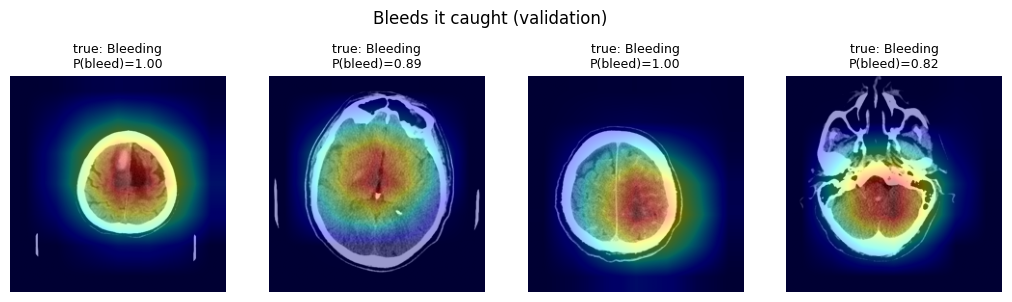

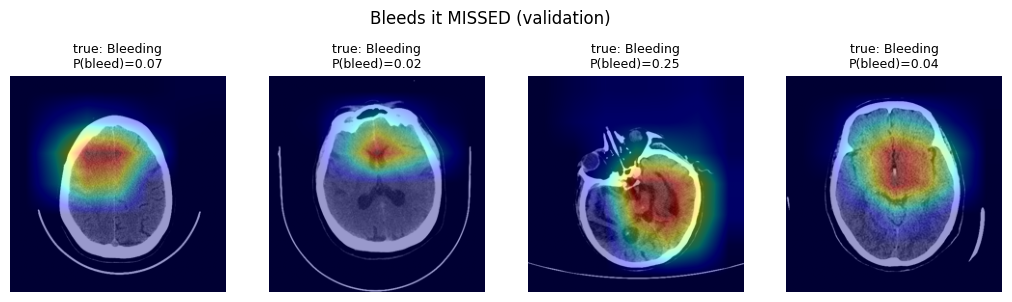

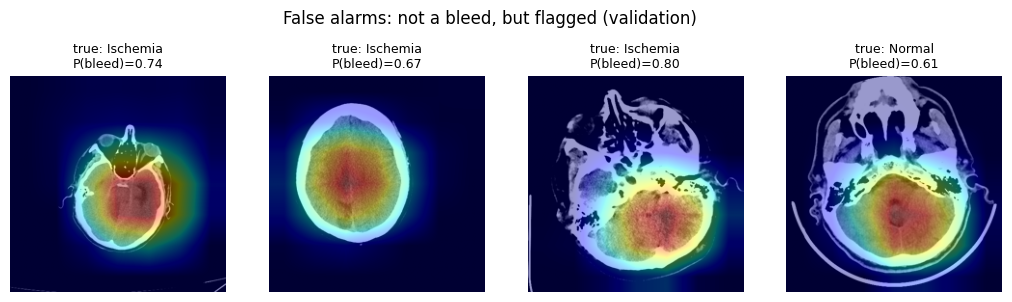

In [18]:
v = val_df.reset_index(drop=True); pv = STORE[FINAL]["val"][:, 1] >= 0.5
def pick(d, mask, n, label):
    return [(d.loc[i, "png"], label(d.loc[i])) for i in np.where(mask)[0][:n]]
vl = lambda r: f"true: {r['cls']}"
gallery(model, tf_ev, pick(v, (v.bleed.values == 1) & pv, 4, vl), "Bleeds it caught (validation)")
gallery(model, tf_ev, pick(v, (v.bleed.values == 1) & ~pv, 4, vl), "Bleeds it MISSED (validation)")
gallery(model, tf_ev, pick(v, (v.bleed.values == 0) & pv, 4, vl), "False alarms: not a bleed, but flagged (validation)")

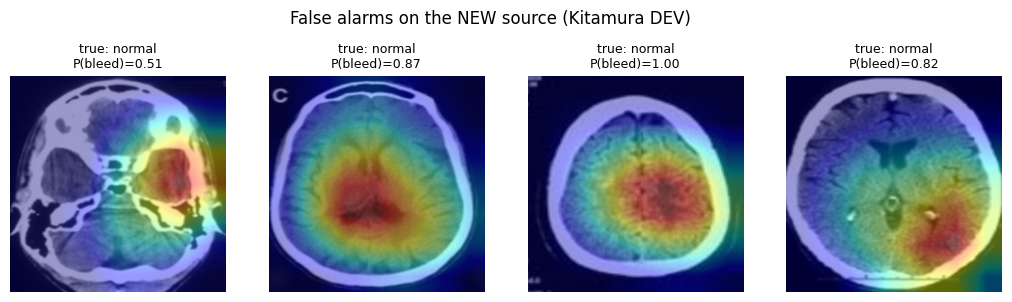

Bleeds missed on the NEW source (Kitamura DEV) -> none


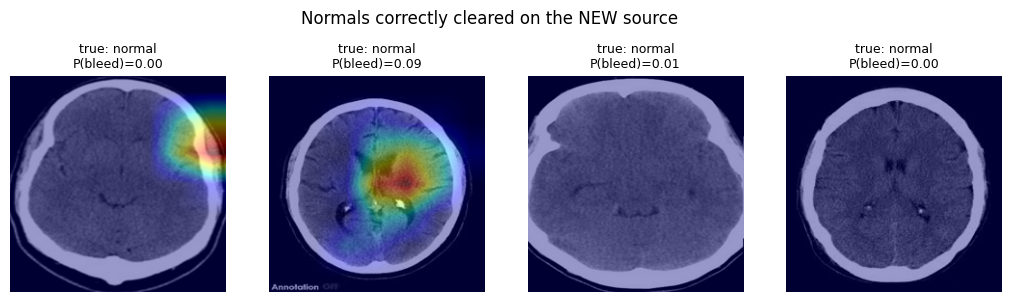

In [19]:
k = kdev.reset_index(drop=True); pk = STORE[FINAL]["kdev"][:, 1] >= 0.5
kl_ = lambda r: "true: bleed" if r["bleed"] == 1 else "true: normal"
gallery(model, tf_ev, pick(k, (k.bleed.values == 0) & pk, 4, kl_), "False alarms on the NEW source (Kitamura DEV)")
gallery(model, tf_ev, pick(k, (k.bleed.values == 1) & ~pk, 4, kl_), "Bleeds missed on the NEW source (Kitamura DEV)")
gallery(model, tf_ev, pick(k, (k.bleed.values == 0) & ~pk, 4, kl_), "Normals correctly cleared on the NEW source")

In [20]:
def pick_threshold(y, p, min_recall=0.95):
    best = None
    for t in np.unique(np.round(p, 4)):
        r, f, _, _ = rec_fa(y, p >= t)
        if r >= min_recall and (best is None or f < best[1] or (f == best[1] and t > best[0])):
            best = (float(t), f, r)
    return best

In [21]:
thr_val, _, _ = pick_threshold(val_df["bleed"].values, STORE[FINAL]["val"][:, 1])
thr_kit, _, _ = pick_threshold(kdev["bleed"].values, STORE[FINAL]["kdev"][:, 1])
print(f"cut-off chosen on validation: {thr_val:.3f} | chosen on Kitamura DEV (local recalibration): {thr_kit:.3f}")

cut-off chosen on validation: 0.214 | chosen on Kitamura DEV (local recalibration): 0.829


In [22]:
# ---- RUN THIS ONCE: it touches the test split and Kitamura FINAL ----
P_te = probs(model, test_df["png"].tolist(), tf_ev)[:, 1]
P_kf = probs(model, kfin["png"].tolist(), tf_ev)[:, 1]
def show(name, y, p, thr):
    y = np.asarray(y); r, f, fn, fp = rec_fa(y, p >= thr)
    print(f"{name} | cut-off {thr:.3f}: bleeds caught {r:.3f} (missed {fn} of {int((y == 1).sum())}), "
          f"false alarms {fp} of {int((y == 0).sum())} ({f:.3f})")
yt, yk = test_df["bleed"].values, kfin["bleed"].values
print("TEST split baseline 'always no bleed': bleeds caught 0.000 (missed", int(yt.sum()), "of", int(yt.sum()), ")")
show("TEST split (same source)", yt, P_te, 0.5)
show("TEST split (same source)", yt, P_te, thr_val)
show("Kitamura FINAL (new source), default cut-off", yk, P_kf, 0.5)
show("Kitamura FINAL (new source), cut-off from our own data", yk, P_kf, thr_val)
show("Kitamura FINAL (new source), recalibrated on its DEV half", yk, P_kf, thr_kit)
print("AUC test:", round(roc_auc_score(yt, P_te), 3), "| AUC Kitamura FINAL:", round(roc_auc_score(yk, P_kf), 3))

TEST split baseline 'always no bleed': bleeds caught 0.000 (missed 164 of 164 )
TEST split (same source) | cut-off 0.500: bleeds caught 0.872 (missed 21 of 164), false alarms 11 of 834 (0.013)
TEST split (same source) | cut-off 0.214: bleeds caught 0.896 (missed 17 of 164), false alarms 35 of 834 (0.042)
Kitamura FINAL (new source), default cut-off | cut-off 0.500: bleeds caught 1.000 (missed 0 of 50), false alarms 15 of 50 (0.300)
Kitamura FINAL (new source), cut-off from our own data | cut-off 0.214: bleeds caught 1.000 (missed 0 of 50), false alarms 24 of 50 (0.480)
Kitamura FINAL (new source), recalibrated on its DEV half | cut-off 0.829: bleeds caught 0.960 (missed 2 of 50), false alarms 11 of 50 (0.220)
AUC test: 0.987 | AUC Kitamura FINAL: 0.94


In [23]:
FINAL = "E0_plain_s3"        # chosen model: plain ResNet18, highest validation AUC of the 4 plain runs
AUG, AUTO = False, False     # plain model: no augmentation, no contrast stretching
model = load_model(FINAL); tf_ev = make_tf(False, AUG, AUTO)

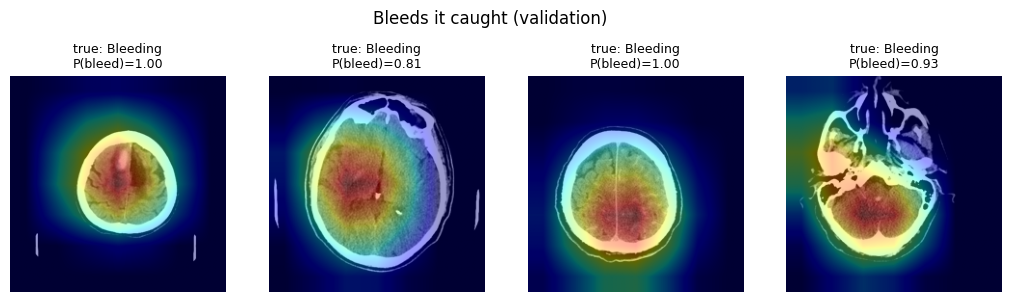

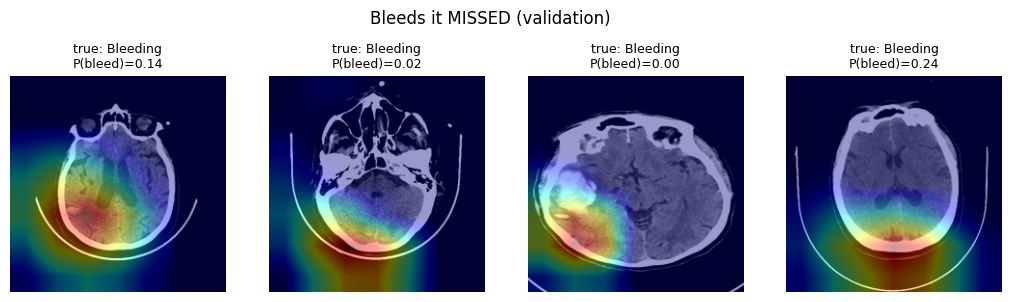

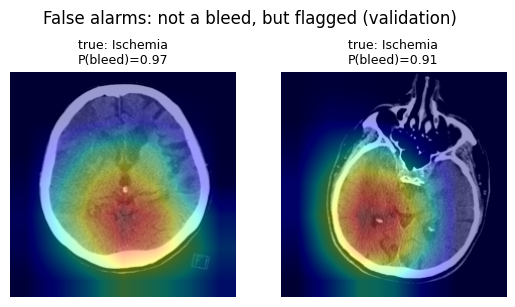

In [24]:
v = val_df.reset_index(drop=True); pv = STORE[FINAL]["val"][:, 1] >= 0.5
def pick(d, mask, n, label):
    return [(d.loc[i, "png"], label(d.loc[i])) for i in np.where(mask)[0][:n]]
vl = lambda r: f"true: {r['cls']}"
gallery(model, tf_ev, pick(v, (v.bleed.values == 1) & pv, 4, vl), "Bleeds it caught (validation)")
gallery(model, tf_ev, pick(v, (v.bleed.values == 1) & ~pv, 4, vl), "Bleeds it MISSED (validation)")
gallery(model, tf_ev, pick(v, (v.bleed.values == 0) & pv, 4, vl), "False alarms: not a bleed, but flagged (validation)")

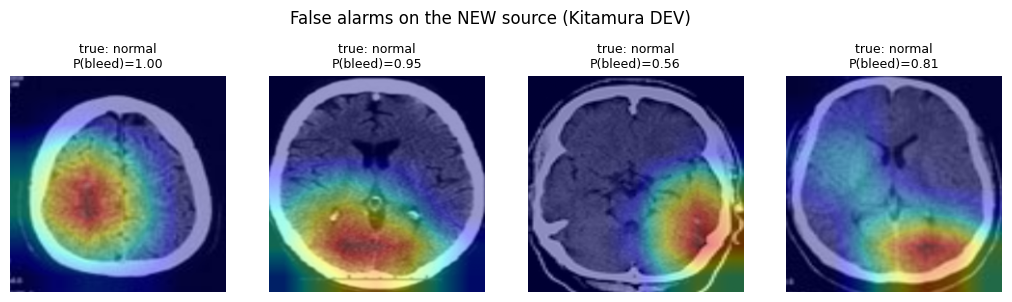

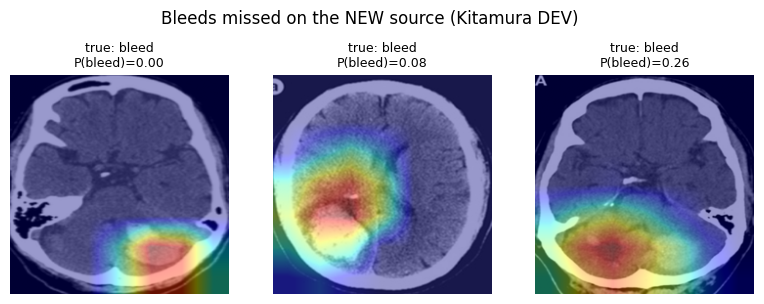

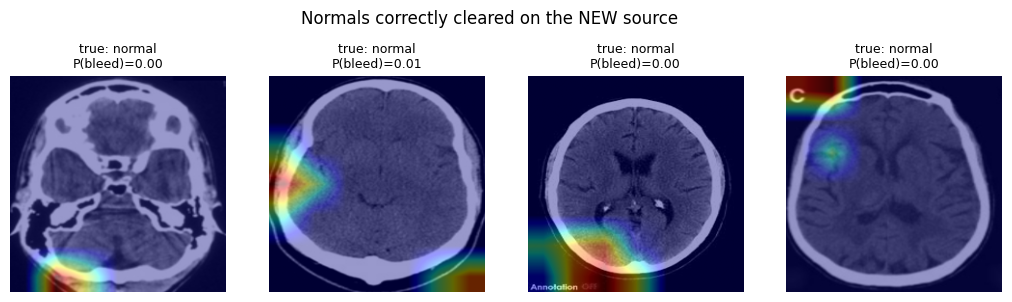

In [25]:
k = kdev.reset_index(drop=True); pk = STORE[FINAL]["kdev"][:, 1] >= 0.5
kl_ = lambda r: "true: bleed" if r["bleed"] == 1 else "true: normal"
gallery(model, tf_ev, pick(k, (k.bleed.values == 0) & pk, 4, kl_), "False alarms on the NEW source (Kitamura DEV)")
gallery(model, tf_ev, pick(k, (k.bleed.values == 1) & ~pk, 4, kl_), "Bleeds missed on the NEW source (Kitamura DEV)")
gallery(model, tf_ev, pick(k, (k.bleed.values == 0) & ~pk, 4, kl_), "Normals correctly cleared on the NEW source")

In [26]:
def pick_threshold(y, p, min_recall=0.95):
    best = None
    for t in np.unique(np.concatenate([[0.0], np.round(p, 4)])):
        r, f, _, _ = rec_fa(y, p >= t)
        if r >= min_recall and (best is None or f < best[1] or (f == best[1] and t > best[0])):
            best = (float(t), f, r)
    return best

names = ["E0_plain", "E0_plain_s1", "E0_plain_s2", "E0_plain_s3"]
tf0 = make_tf(False)
yt, yk = test_df["bleed"].values, kfin["bleed"].values
rows = []
for nm in names:
    m = load_model(nm)
    Pt = probs(m, test_df["png"].tolist(), tf0)[:, 1]
    Pk = probs(m, kfin["png"].tolist(), tf0)[:, 1]
    tk = pick_threshold(kdev["bleed"].values, STORE[nm]["kdev"][:, 1])[0]
    r_t, f_t, _, _ = rec_fa(yt, Pt >= 0.5)
    r_k, f_k, _, _ = rec_fa(yk, Pk >= 0.5)
    r_c, f_c, _, _ = rec_fa(yk, Pk >= tk)
    rows.append({"model": nm,
        "test recall@0.5": r_t, "test false-alarm@0.5": f_t, "test AUC": roc_auc_score(yt, Pt),
        "Kit recall@0.5": r_k, "Kit false-alarm@0.5": f_k, "Kit AUC": roc_auc_score(yk, Pk),
        "Kit recalibrated recall": r_c, "Kit recalibrated false-alarm": f_c})
res = pd.DataFrame(rows).set_index("model")
print(res.round(3).T)
fmt = lambda s: f"{s.mean():.3f} ({s.min():.3f}-{s.max():.3f})"
print("\nmean (min-max) over the 4 models:")
print(res.apply(fmt).to_string())

model                         E0_plain  E0_plain_s1  E0_plain_s2  E0_plain_s3
test recall@0.5                  0.933        0.896        0.921        0.884
test false-alarm@0.5             0.014        0.007        0.004        0.002
test AUC                         0.992        0.995        0.996        0.996
Kit recall@0.5                   0.960        0.920        0.860        0.920
Kit false-alarm@0.5              0.180        0.140        0.100        0.200
Kit AUC                          0.945        0.958        0.951        0.937
Kit recalibrated recall          1.000        1.000        0.880        0.960
Kit recalibrated false-alarm     0.480        0.360        0.140        0.220

mean (min-max) over the 4 models:
test recall@0.5                 0.909 (0.884-0.933)
test false-alarm@0.5            0.007 (0.002-0.014)
test AUC                        0.995 (0.992-0.996)
Kit recall@0.5                  0.915 (0.860-0.960)
Kit false-alarm@0.5             0.155 (0.100-0.200)
Kit

In [27]:
def adapt_and_test(base_name, n, seed, epochs=5, lr=1e-4):
    torch.manual_seed(seed)
    model = load_model(base_name)
    tf = make_tf(False)
    if n > 0:
        sub = pd.concat([kdev[kdev["bleed"] == c].sample(n // 2, random_state=seed) for c in (0, 1)])
        dl = DataLoader(DS(sub["png"], sub["bleed"].tolist(), tf), batch_size=16, shuffle=True, num_workers=2)
        opt = torch.optim.Adam(model.parameters(), lr=lr)
        loss_fn = nn.CrossEntropyLoss()
        for _ in range(epochs):
            model.train()
            for xb, yb in dl:
                opt.zero_grad(); loss_fn(model(xb.to(device)), yb.to(device)).backward(); opt.step()
    Pk = probs(model, kfin["png"].tolist(), tf)[:, 1]
    Pv = probs(model, val_df["png"].tolist(), tf)[:, 1]
    r, f, _, _ = rec_fa(kfin["bleed"], Pk >= 0.5)
    rv, fv, _, _ = rec_fa(val_df["bleed"], Pv >= 0.5)
    return {"local scans used": n, "Kit recall": r, "Kit false-alarm": f,
            "Kit AUC": roc_auc_score(kfin["bleed"], Pk), "main-source recall": rv, "main-source false-alarm": fv}

out = []
for n in [0, 10, 20, 40, 100]:
    for s in ([0] if n == 0 else [1, 2, 3]):
        out.append(adapt_and_test("E0_plain_s3", n, s))
adapt = pd.DataFrame(out)
fmt = lambda s: f"{s.mean():.3f} ({s.min():.3f}-{s.max():.3f})"
adapt.groupby("local scans used").agg(fmt).T

local scans used,0,10,20,40,100
Kit recall,0.920 (0.920-0.920),0.873 (0.840-0.900),0.913 (0.880-0.940),0.940 (0.900-0.960),0.953 (0.940-0.980)
Kit false-alarm,0.200 (0.200-0.200),0.067 (0.060-0.080),0.053 (0.040-0.080),0.013 (0.000-0.040),0.013 (0.000-0.020)
Kit AUC,0.937 (0.937-0.937),0.968 (0.954-0.985),0.981 (0.970-0.995),0.992 (0.977-0.999),0.997 (0.997-0.998)
main-source recall,0.884 (0.884-0.884),0.811 (0.774-0.835),0.774 (0.726-0.823),0.783 (0.756-0.823),0.868 (0.829-0.915)
main-source false-alarm,0.002 (0.002-0.002),0.001 (0.000-0.001),0.000 (0.000-0.000),0.000 (0.000-0.000),0.013 (0.006-0.024)


In [2]:
import os
print("inputs:", os.listdir("/kaggle/input"))
print("datasets:", os.listdir("/kaggle/input/datasets") if os.path.exists("/kaggle/input/datasets") else "no /datasets folder")

# ===== data, splits, logger =====
import os, numpy as np, pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

SEED = 42
CLASSES = ["Normal", "Bleeding", "Ischemia"]
base = "/kaggle/input/datasets/ozguraslank/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset"
kb = "/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage"

# Main data: same file order and seed as our first run, so the splits are identical
rows = []
for cls in CLASSES:
    for f in sorted(os.listdir(f"{base}/{cls}/PNG")):
        rows.append({"id": f[:-4], "cls": cls, "png": f"{base}/{cls}/PNG/{f}"})
df = pd.DataFrame(rows)
df["bleed"] = (df["cls"] == "Bleeding").astype(int)
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["cls"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["cls"], random_state=SEED)

# Same-source held-out set: label is "any stroke"
ext = pd.read_csv(f"{base}/External_Test/labels.csv")
ext["png"] = [f"{base}/External_Test/PNG/{i}.png" for i in ext["image_id"]]
ext["stroke"] = ext["Stroke"].astype(int)

# Different-source set (Kitamura), split in two halves:
#   DEV   = used to compare experiments and choose settings
#   FINAL = looked at once, at the very end
kl = pd.read_csv(f"{kb}/labels.csv"); kl.columns = [c.strip() for c in kl.columns]
lab = kl.columns[1]
def kpath(i):
    s = str(i)
    return f"{kb}/head_ct/head_ct/{s}" if s.endswith(".png") else f"{kb}/head_ct/head_ct/{int(i):03d}.png"
kdf = pd.DataFrame({"png": [kpath(i) for i in kl.iloc[:, 0]], "bleed": kl[lab].astype(int).values})
kdev, kfin = train_test_split(kdf, test_size=0.5, stratify=kdf["bleed"], random_state=SEED)
print("train/val/test:", len(train_df), len(val_df), len(test_df), "| ExtTest:", len(ext), "| Kitamura dev/final:", len(kdev), len(kfin))
print("Kitamura dev:", kdev["bleed"].value_counts().to_dict(), "| final:", kfin["bleed"].value_counts().to_dict())

def rec_fa(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    tp = int(((y == 1) & (pred == 1)).sum()); fn = int(((y == 1) & (pred == 0)).sum())
    fp = int(((y == 0) & (pred == 1)).sum()); neg = int((y == 0).sum())
    return tp / (tp + fn), fp / neg, fn, fp

LOG, STORE = [], {}
def evaluate_all(name, model, tf_ev, thr=0.5):
    P_val = probs(model, val_df["png"].tolist(), tf_ev)
    P_ext = probs(model, ext["png"].tolist(), tf_ev)
    P_kd = probs(model, kdev["png"].tolist(), tf_ev)
    STORE[name] = {"val": P_val, "ext": P_ext, "kdev": P_kd}
    r1, f1, _, _ = rec_fa(val_df["bleed"], P_val[:, 1] >= thr)
    r2, f2, _, _ = rec_fa(ext["stroke"], (1 - P_ext[:, 0]) >= thr)
    r3, f3, _, _ = rec_fa(kdev["bleed"], P_kd[:, 1] >= thr)
    LOG.append({"experiment": name,
        "val bleed recall": round(r1, 3), "val false-alarm rate": round(f1, 3),
        "val AUC": round(roc_auc_score(val_df["bleed"], P_val[:, 1]), 3),
        "ExtTest stroke recall": round(r2, 3), "ExtTest false-alarm rate": round(f2, 3),
        "KitDev bleed recall": round(r3, 3), "KitDev false-alarm rate": round(f3, 3),
        "KitDev AUC": round(roc_auc_score(kdev["bleed"], P_kd[:, 1]), 3)})
    log = pd.DataFrame(LOG)
    log.to_csv("/kaggle/working/experiment_log.csv", index=False)
    return log.set_index("experiment").T

# ===== model code =====
import torch, torch.nn as nn, torchvision
from PIL import ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

device = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def autocontrast(im):
    return ImageOps.autocontrast(im, cutoff=1)

def make_tf(train, aug=False, auto=False):
    steps = [T.Lambda(autocontrast)] if auto else []
    if train and aug:
        steps += [T.RandomResizedCrop(224, scale=(0.7, 1.0)), T.RandomRotation(10),
                  T.ColorJitter(brightness=0.3, contrast=0.3)]
    else:
        steps += [T.Resize((224, 224))]
    return T.Compose(steps + [T.ToTensor(), T.Normalize(MEAN, STD)])

class DS(Dataset):
    def __init__(self, paths, labels, tf):
        self.p, self.y, self.tf = list(paths), list(labels), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def probs(model, paths, tf_ev):
    dl = DataLoader(DS(paths, [0] * len(paths), tf_ev), batch_size=64, shuffle=False, num_workers=2)
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in dl:
            out.append(model(xb.to(device)).softmax(1).cpu().numpy())
    return np.concatenate(out)

def train_model(name, arch="resnet18", epochs=6, aug=False, auto=False, lr=3e-4):
    torch.manual_seed(SEED); np.random.seed(SEED)
    tf_tr, tf_ev = make_tf(True, aug, auto), make_tf(False, aug, auto)
    tr_dl = DataLoader(DS(train_df["png"], [CLASSES.index(c) for c in train_df["cls"]], tf_tr),
                       batch_size=64, shuffle=True, num_workers=2)
    model = getattr(torchvision.models, arch)(weights="DEFAULT")
    model.fc = nn.Linear(model.fc.in_features, 3)
    model = model.to(device)
    counts = train_df["cls"].value_counts()
    w = torch.tensor([len(train_df) / (3 * counts[c]) for c in CLASSES], dtype=torch.float32).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    best_auc, best_state = 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            opt.zero_grad()
            loss_fn(model(xb.to(device)), yb.to(device)).backward()
            opt.step()
        auc = roc_auc_score(val_df["bleed"], probs(model, val_df["png"].tolist(), tf_ev)[:, 1])
        print(f"{name} epoch {epoch + 1}: validation bleed AUC {auc:.3f}")
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, f"/kaggle/working/{name}.pt")
    return model, tf_ev

# ===== seed helper =====
def run(config, seed, **kw):
    global SEED
    SEED = seed
    name = f"{config}_s{seed}"
    model, tf_ev = train_model(name, **kw)
    return evaluate_all(name, model, tf_ev)

def seed_summary():
    log = pd.DataFrame(LOG)
    m = log["experiment"].str.extract(r"^(.*)_s(\d+)$")
    log["config"] = m[0]
    seeds = log.dropna(subset=["config"])
    cols = [c for c in log.columns if c not in ("experiment", "config")]
    fmt = lambda s: f"{s.mean():.3f} ({s.min():.3f}-{s.max():.3f})"
    return seeds.groupby("config")[cols].agg(fmt).T

# ===== train the demo model only if its weights are missing =====
if os.path.exists("/kaggle/working/E0_plain_s3.pt"):
    print("E0_plain_s3.pt already exists, skipping training")
else:
    run("E0_plain", 3, epochs=5)
    print("trained and saved E0_plain_s3.pt")

inputs: ['datasets']
datasets: ['felipekitamura', 'ozguraslank']
train/val/test: 4655 997 998 | ExtTest: 200 | Kitamura dev/final: 100 100
Kitamura dev: {0: 50, 1: 50} | final: {1: 50, 0: 50}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 170MB/s] 


E0_plain_s3 epoch 1: validation bleed AUC 0.979
E0_plain_s3 epoch 2: validation bleed AUC 0.983
E0_plain_s3 epoch 3: validation bleed AUC 0.984
E0_plain_s3 epoch 4: validation bleed AUC 0.996
E0_plain_s3 epoch 5: validation bleed AUC 0.997
trained and saved E0_plain_s3.pt


In [3]:
import os
print([f for f in os.listdir("/kaggle/working") if f.endswith(".pt")])

['E0_plain_s3.pt']


In [4]:
import shutil, os
os.makedirs("/kaggle/working/examples", exist_ok=True)
pick_ = pd.concat([kdev[kdev.bleed == 1].head(3), kdev[kdev.bleed == 0].head(3)])
for i, (_, r) in enumerate(pick_.iterrows()):
    ext_ = os.path.splitext(r["png"])[1]
    shutil.copy(r["png"], f"/kaggle/working/examples/kitamura_{'bleed' if r.bleed == 1 else 'normal'}_{i}{ext_}")
print(os.listdir("/kaggle/working/examples"))

['kitamura_bleed_0.png', 'kitamura_normal_4.png', 'kitamura_bleed_2.png', 'kitamura_bleed_1.png', 'kitamura_normal_3.png', 'kitamura_normal_5.png']


In [13]:
# !pip install gradio

In [26]:
%%writefile /kaggle/working/app.py
"""BleedCheck CT: a research prototype. Not medical advice."""
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
from torchvision import transforms as T
import matplotlib.cm as cm
import gradio as gr

CLASSES = ["Normal", "Bleeding", "Ischemia"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
WEIGHTS = next((p for p in ["E0_plain_s3.pt", "/kaggle/working/E0_plain_s3.pt"] if os.path.exists(p)), "E0_plain_s3.pt")
device = "cpu"  # small model, CPU is enough for one image

model = torchvision.models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 3)
model.load_state_dict(torch.load(WEIGHTS, map_location=device))
model.to(device).eval()

tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])


def gradcam(x, class_idx=1):
    feats, grads = [], []

    def fwd(m, i, o):
        feats.append(o)
        o.register_hook(lambda g: grads.append(g))

    h = model.layer4.register_forward_hook(fwd)
    model.zero_grad()
    out = model(x)
    out[0, class_idx].backward()
    h.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()
    return cam, out.softmax(1)[0].detach().cpu().numpy()

Overwriting /kaggle/working/app.py


In [27]:
%%writefile -a /kaggle/working/app.py

# ---- palette: change these colours and nothing else needs touching ----
PALETTE = {
    "bg": "#F3F4FB",          # page background
    "card": "#FFFFFF",        # panels
    "text": "#23264A",        # main text
    "muted": "#585D78",       # small text
    "accent": "#5B5BD6",      # buttons, highlights
    "accent_dark": "#3F3FB0", # headings, big numbers
    "soft": "#ECEEFC",        # light tint of the accent
    "line": "#E0E3F3",        # borders
    "flag": "#D6336C",        # "possible bleed" colour
    "flag_bg": "#FFF0F5",     # "possible bleed" background
    "warn": "#9A4A06",        # disclaimer text
    "warn_bg": "#FFF6E5",     # disclaimer background
}

CSS_TEMPLATE = """
@import url('https://fonts.googleapis.com/css2?family=Sora:wght@500;700;800&family=Inter:wght@400;500;600&display=swap');
.gradio-container, .dark .gradio-container {
  --body-background-fill: __BG__; --background-fill-primary: __CARD__; --background-fill-secondary: __BG__;
  --block-background-fill: __CARD__; --block-border-color: __LINE__; --border-color-primary: __LINE__;
  --body-text-color: __TEXT__; --block-label-text-color: __MUTED__; --block-title-text-color: __TEXT__;
  --input-background-fill: __CARD__; --button-primary-background-fill: __ACCENT__;
  --button-primary-background-fill-hover: __ACCENT_DARK__; --button-primary-text-color: #FFFFFF;
  --color-accent: __ACCENT__; --slider-color: __ACCENT__;
  --block-radius: 20px; --button-large-radius: 14px; --block-shadow: 0 18px 36px -24px rgba(63,63,176,.45);
  font-family: 'Inter', 'Segoe UI', system-ui, sans-serif;
  background: radial-gradient(900px 500px at 0% 0%, #E6E8FB, transparent), radial-gradient(800px 500px at 100% 30%, #F8E3EE, transparent), __BG__ !important;
  color: __TEXT__ !important; max-width: 1120px !important; margin: 0 auto;
}
footer { display: none !important; }
.bc-bare { background: transparent !important; border: none !important; box-shadow: none !important; padding: 0 !important; }

/* ---------- hero: giant word behind a floating CT slice ---------- */
.bc-hero { position: relative; overflow: hidden; height: 470px; border-radius: 30px; perspective: 900px;
  background: radial-gradient(700px 320px at 15% 0%, #FFFFFF, transparent), radial-gradient(600px 360px at 95% 100%, #F5D3E6, transparent),
              linear-gradient(180deg, #F4F5FD, #DDE0F6); box-shadow: 0 30px 60px -34px rgba(63,63,176,.55); }
.bc-bar { position: absolute; z-index: 5; top: 20px; left: 24px; right: 24px; display: flex; justify-content: space-between; align-items: center; }
.bc-brand { font-family: 'Sora', sans-serif; font-weight: 700; color: __ACCENT_DARK__; font-size: 1rem; letter-spacing: .02em; }
.bc-pill { padding: 5px 14px; border-radius: 999px; font-size: .78rem; font-weight: 600; color: __ACCENT_DARK__;
  background: rgba(255,255,255,.7); border: 1px solid rgba(255,255,255,.95); backdrop-filter: blur(10px); }
.bc-giant { position: absolute; z-index: 1; left: 0; right: 0; top: 44%; transform: translateY(-50%); text-align: center;
  font-family: 'Sora', sans-serif; font-weight: 800; line-height: 1; letter-spacing: -.02em; white-space: nowrap;
  font-size: clamp(2.7rem, 11vw, 8.8rem); background: linear-gradient(180deg, #8A8FE0 0%, #C9CCF4 85%);
  -webkit-background-clip: text; background-clip: text; color: transparent; -webkit-text-fill-color: transparent; user-select: none; }
.bc-stage { position: absolute; z-index: 3; left: 50%; top: 44%; width: 224px; height: 262px; margin: -131px 0 0 -112px; animation: bc-float 6s ease-in-out infinite; }
.bc-disc { position: relative; width: 100%; height: 100%; border-radius: 50%; overflow: hidden;
  box-shadow: 0 0 0 6px rgba(255,255,255,.55), 0 30px 60px -10px rgba(35,38,74,.65), 0 0 90px 10px rgba(91,91,214,.45); }
.bc-disc svg { width: 100%; height: 100%; display: block; }
.bc-scan { position: absolute; left: 0; right: 0; height: 46px; top: -20%;
  background: linear-gradient(180deg, transparent, rgba(190,196,255,.75), transparent); mix-blend-mode: screen; animation: bc-scan 3.6s ease-in-out infinite; }
.bc-hot { animation: bc-pulse 2.4s ease-in-out infinite; transform-origin: 262px 250px; }
.bc-pod { position: absolute; z-index: 2; left: 50%; bottom: 40px; width: 360px; height: 62px; margin-left: -180px; border-radius: 50%;
  background: radial-gradient(ellipse at center, rgba(255,255,255,.95) 0%, rgba(160,165,240,.55) 45%, rgba(91,91,214,0) 72%);
  border: 2px solid rgba(255,255,255,.9); box-shadow: 0 0 40px 6px rgba(91,91,214,.35), inset 0 0 20px rgba(255,255,255,.9); }
.bc-sub { position: absolute; z-index: 5; left: 26px; bottom: 22px; right: 26px; display: flex; justify-content: space-between; align-items: end; gap: 14px; flex-wrap: wrap; }
.bc-sub p { margin: 0; max-width: 430px; font-size: 1.02rem; color: __TEXT__; font-weight: 500; line-height: 1.4; }
.bc-chip { padding: 7px 14px; border-radius: 12px; font-size: .8rem; font-weight: 600; color: #FFFFFF;
  background: linear-gradient(135deg, __ACCENT_DARK__, __ACCENT__); box-shadow: 0 10px 20px -8px rgba(63,63,176,.7); }
@keyframes bc-float { 0%,100% { transform: translateY(0) rotateY(-9deg) rotateX(3deg); } 50% { transform: translateY(-14px) rotateY(9deg) rotateX(-2deg); } }
@keyframes bc-scan { 0% { top: -20%; } 100% { top: 105%; } }
@keyframes bc-pulse { 0%,100% { transform: scale(1); opacity: .85; } 50% { transform: scale(1.35); opacity: 1; } }
@media (prefers-reduced-motion: reduce) { .bc-stage, .bc-scan, .bc-hot { animation: none; } }

/* ---------- glass cards ---------- */
.bc-stats { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin: 16px 0; }
.bc-glass { background: rgba(255,255,255,.72); border: 1px solid rgba(255,255,255,.95); border-radius: 22px; backdrop-filter: blur(14px);
  box-shadow: 0 22px 40px -26px rgba(63,63,176,.55); transition: transform .25s ease, box-shadow .25s ease; }
.bc-glass:hover { transform: perspective(700px) rotateX(4deg) translateY(-5px); box-shadow: 0 30px 46px -24px rgba(63,63,176,.6); }
.bc-stat { padding: 18px 20px; }
.bc-stat b { display: block; font-family: 'Sora', sans-serif; font-size: 2rem; line-height: 1.1; color: __ACCENT_DARK__; }
.bc-stat span { font-size: .9rem; color: __MUTED__; }
.bc-warn { border: 1px solid #F0CF9B; background: __WARN_BG__; border-radius: 14px; padding: 11px 16px; color: __WARN__; font-size: .93rem; margin-bottom: 8px; }

/* ---------- result ---------- */
.bc-verdict { display: flex; gap: 18px; align-items: center; padding: 18px 20px; border-radius: 22px; border: 1px solid __LINE__; background: __CARD__;
  box-shadow: 0 22px 40px -28px rgba(63,63,176,.55); }
.bc-verdict.flag { border-color: __FLAG__; background: linear-gradient(135deg, __FLAG_BG__, #FFFFFF); }
.bc-verdict.clear { border-color: __ACCENT__; background: linear-gradient(135deg, __SOFT__, #FFFFFF); }
.bc-ring { --p: 0; --c: __ACCENT__; flex: none; width: 96px; height: 96px; border-radius: 50%; position: relative; display: grid; place-items: center;
  background: conic-gradient(var(--c) calc(var(--p) * 1%), #E1E4F4 0); }
.bc-ring::before { content: ""; position: absolute; inset: 11px; border-radius: 50%; background: #FFFFFF; }
.bc-ring b { position: relative; font-family: 'Sora', sans-serif; font-size: 1.25rem; color: __TEXT__; }
.bc-verdict.flag .bc-ring { --c: __FLAG__; }
.bc-verdict h3 { margin: 0 0 6px; font-family: 'Sora', sans-serif; font-size: 1.2rem; color: __TEXT__; }
.bc-verdict p { margin: 0; font-size: .93rem; color: #3A3F5C; line-height: 1.45; }
.bc-bars { margin-top: 12px; padding: 12px 18px; }
.bc-row { display: grid; grid-template-columns: 82px 1fr 52px; gap: 10px; align-items: center; margin: 9px 0; font-size: .92rem; }
.bc-track { height: 10px; background: #E1E4F4; border-radius: 999px; overflow: hidden; }
.bc-fill { height: 100%; background: #7B82A8; border-radius: 999px; }
.bc-fill.main { background: linear-gradient(90deg, __ACCENT__, #8E7CF0); }
.bc-num { text-align: right; font-variant-numeric: tabular-nums; color: __TEXT__; }

/* ---------- steps + notes ---------- */
.bc-steps { display: grid; grid-template-columns: repeat(3, 1fr); gap: 14px; margin: 18px 0 8px; }
.bc-step { padding: 18px 20px; }
.bc-step i { display: inline-grid; place-items: center; width: 30px; height: 30px; border-radius: 10px; font-style: normal; font-weight: 700; color: #FFFFFF;
  background: linear-gradient(135deg, __ACCENT_DARK__, __ACCENT__); margin-bottom: 8px; }
.bc-step h4 { margin: 0 0 4px; font-family: 'Sora', sans-serif; font-size: 1.02rem; color: __TEXT__; }
.bc-step p { margin: 0; font-size: .9rem; color: __MUTED__; line-height: 1.45; }
.bc-note { font-size: .9rem; color: __MUTED__; line-height: 1.55; margin-top: 12px; }
.bc-note b { color: __TEXT__; }
@media (max-width: 760px) {
  .bc-stats, .bc-steps { grid-template-columns: 1fr; }
  .bc-hero { height: 520px; }
  .bc-giant { top: 36%; font-size: 3.2rem; }
  .bc-stage { top: 36%; width: 160px; height: 188px; margin: -94px 0 0 -80px; }
  .bc-pod { bottom: 150px; width: 230px; height: 44px; margin-left: -115px; }
  .bc-sub { flex-direction: column; align-items: flex-start; }
  .bc-sub p { font-size: .92rem; }
}
"""
CSS = CSS_TEMPLATE
for _k, _v in PALETTE.items():
    CSS = CSS.replace("__" + _k.upper() + "__", _v)

Appending to /kaggle/working/app.py


In [28]:
%%writefile -a /kaggle/working/app.py

HERO_HTML = """
<div class="bc-hero">
  <div class="bc-bar"><span class="bc-brand">BleedCheck CT</span><span class="bc-pill">Research prototype</span></div>
  <div class="bc-giant">BLEEDCHECK</div>
  <div class="bc-pod"></div>
  <div class="bc-stage"><div class="bc-disc">
    <svg viewBox="0 0 400 460" xmlns="http://www.w3.org/2000/svg" aria-label="Illustration of a head CT slice">
      <defs>
        <radialGradient id="bcBone" cx="50%" cy="45%" r="60%"><stop offset="0" stop-color="#30346E"/><stop offset="1" stop-color="#0B0D2B"/></radialGradient>
        <radialGradient id="bcBrain" cx="50%" cy="42%" r="62%"><stop offset="0" stop-color="#7479C8"/><stop offset=".7" stop-color="#3B3F85"/><stop offset="1" stop-color="#1D2050"/></radialGradient>
        <linearGradient id="bcRim" x1="0" y1="0" x2="1" y2="1"><stop offset="0" stop-color="#FFFFFF"/><stop offset=".5" stop-color="#C8CCFA"/><stop offset="1" stop-color="#8E92E8"/></linearGradient>
        <radialGradient id="bcHot" cx="50%" cy="50%" r="50%"><stop offset="0" stop-color="#FFB4CE"/><stop offset=".55" stop-color="#F0527F" stop-opacity=".75"/><stop offset="1" stop-color="#F0527F" stop-opacity="0"/></radialGradient>
        <filter id="bcTex" x="0" y="0" width="100%" height="100%">
          <feTurbulence type="fractalNoise" baseFrequency="0.03 0.045" numOctaves="3" seed="11" result="n"/>
          <feColorMatrix in="n" type="matrix" values="0 0 0 0 0.80  0 0 0 0 0.82  0 0 0 0 1  0 0 0 1.5 -0.55" result="m"/>
          <feComposite in="m" in2="SourceGraphic" operator="in"/>
        </filter>
      </defs>
      <rect width="400" height="460" fill="#0B0D2B"/>
      <ellipse cx="200" cy="230" rx="176" ry="208" fill="none" stroke="url(#bcRim)" stroke-width="16"/>
      <ellipse cx="200" cy="230" rx="160" ry="192" fill="url(#bcBone)"/>
      <ellipse cx="200" cy="230" rx="146" ry="176" fill="url(#bcBrain)"/>
      <ellipse cx="200" cy="230" rx="146" ry="176" fill="#000" filter="url(#bcTex)" opacity=".75"/>
      <path d="M200 70 C197 150 203 310 200 392" stroke="#171A47" stroke-width="3" fill="none" opacity=".7"/>
      <path d="M188 170 C166 184 164 258 186 284 C196 256 196 208 188 170Z" fill="#0A0C2A" opacity=".88"/>
      <path d="M212 170 C234 184 236 258 214 284 C204 256 204 208 212 170Z" fill="#0A0C2A" opacity=".88"/>
      <ellipse class="bc-hot" cx="262" cy="250" rx="34" ry="30" fill="url(#bcHot)"/>
    </svg>
    <div class="bc-scan"></div>
  </div></div>
  <div class="bc-sub">
    <p>Upload one head CT slice. See whether our model flags a possible brain bleed, and what drove the score.</p>
    <span class="bc-chip">Not medical advice</span>
  </div>
</div>"""

STATS_HTML = """<div class="bc-stats">
<div class="bc-glass bc-stat"><b>~91%</b><span>of bleeds caught on data like its training data</span></div>
<div class="bc-glass bc-stat"><b>10–20%</b><span>of normal scans wrongly flagged on a second source</span></div>
<div class="bc-glass bc-stat"><b>20% → 1%</b><span>false alarms after tuning on 100 local scans (our test)</span></div></div>"""

WARN_HTML = """<div class="bc-warn"><b>This project is a prototype and is not medical advice.</b>
Please upload only public or example images, never a real patient's scan. Your image is processed in memory and is not saved.</div>"""

EMPTY_HTML = """<div class="bc-verdict"><div class="bc-ring" style="--p:0"><b>–</b></div>
<div><h3>Waiting for a scan</h3><p>Upload a head CT slice or click an example below, then press <b>Analyse</b>.</p></div></div>"""

STEPS_HTML = """<div class="bc-steps">
<div class="bc-glass bc-step"><i>1</i><h4>Upload a slice</h4><p>One axial head CT image (PNG or JPG). Public or example images only.</p></div>
<div class="bc-glass bc-step"><i>2</i><h4>The model scores it</h4><p>A ResNet18 trained on public CT data gives Normal, Bleeding and Ischemia scores.</p></div>
<div class="bc-glass bc-step"><i>3</i><h4>Look closer</h4><p>A flag means a human should review the scan. The heatmap shows what drove the score.</p></div></div>"""

NOTES_HTML = """<div class="bc-note"><b>How to read this.</b> A flag means <i>look closer</i>, not a diagnosis. A clear result does
not rule out a bleed: in our tests the model missed roughly 1 in 11 bleeds. The heatmap shows what drove the score, not where a bleed is;
it often highlighted the skull edge or scan background.<br>
<b>Data.</b> Trained on 6,650 slices of the TEKNOFEST-2021 stroke CT set; tested on a second public source (Kitamura, CC0). On a new source it
needs local checking before any real use.</div>"""


def verdict_html(p_bleed, cutoff):
    if p_bleed >= cutoff:
        cls, title = "flag", "Possible bleed flagged"
        text = "The bleed score is above your threshold. This is a prompt to look closer, not a diagnosis."
    else:
        cls, title = "clear", "No bleed flagged"
        text = "The bleed score is below your threshold. This does not rule out a bleed."
    return (f'<div class="bc-verdict {cls}"><div class="bc-ring" style="--p:{p_bleed * 100:.0f}"><b>{p_bleed:.2f}</b></div>'
            f'<div><h3>{title}</h3><p>Bleed score {p_bleed:.2f} (threshold {cutoff:.2f}). {text}</p></div></div>')


def bars_html(scores):
    rows = ""
    for name, v in scores.items():
        main = " main" if name == "Bleeding" else ""
        rows += (f'<div class="bc-row"><span>{name}</span>'
                 f'<div class="bc-track"><div class="bc-fill{main}" style="width:{v * 100:.1f}%"></div></div>'
                 f'<span class="bc-num">{v * 100:.0f}%</span></div>')
    return f'<div class="bc-glass bc-bars">{rows}</div>'

Appending to /kaggle/working/app.py


In [29]:
%%writefile -a /kaggle/working/app.py

def analyse(img, cutoff):
    if img is None:
        return EMPTY_HTML, "", None
    img = img.convert("RGB")
    x = tf(img).unsqueeze(0).to(device)
    cam, p = gradcam(x)
    g = np.asarray(img.convert("L").resize((224, 224)), dtype=np.float32) / 255
    heat = cm.jet(cam)[..., :3]
    over = (0.6 * np.stack([g] * 3, -1) + 0.4 * heat).clip(0, 1)
    over = Image.fromarray((over * 255).astype("uint8")).resize((448, 448))
    scores = {c: float(p[i]) for i, c in enumerate(CLASSES)}
    return verdict_html(float(p[1]), cutoff), bars_html(scores), over


with gr.Blocks(title="BleedCheck CT") as demo:
    gr.HTML("<style>" + CSS + "</style>", elem_classes="bc-bare")
    gr.HTML(HERO_HTML, elem_classes="bc-bare")
    gr.HTML(STATS_HTML, elem_classes="bc-bare")
    gr.HTML(WARN_HTML, elem_classes="bc-bare")
    with gr.Row(equal_height=False):
        with gr.Column(scale=1):
            inp = gr.Image(type="pil", label="Head CT slice", height=380)
            cutoff = gr.Slider(0.05, 0.95, value=0.5, step=0.05, label="Flag threshold (lower = flags more scans)")
            btn = gr.Button("Analyse", variant="primary")
        with gr.Column(scale=1):
            verdict = gr.HTML(EMPTY_HTML, elem_classes="bc-bare")
            bars = gr.HTML("", elem_classes="bc-bare")
            heat = gr.Image(label="Where the model looked (Grad-CAM)", height=380, interactive=False)
    examples_dir = "examples"
    if os.path.isdir(examples_dir):
        files = sorted(os.path.join(examples_dir, f) for f in os.listdir(examples_dir) if f.lower().endswith((".png", ".jpg", ".jpeg")))
        if files:
            gr.Examples(examples=[[f, 0.5] for f in files], inputs=[inp, cutoff], outputs=[verdict, bars, heat],
                        fn=analyse, run_on_click=True, cache_examples=False,
                        label="Public example scans (Kitamura, CC0). Click one to try it.")
    gr.HTML(STEPS_HTML, elem_classes="bc-bare")
    gr.HTML(NOTES_HTML, elem_classes="bc-bare")
    btn.click(analyse, [inp, cutoff], [verdict, bars, heat])

if __name__ == "__main__":
    demo.launch()

Appending to /kaggle/working/app.py


In [30]:
import os
p = "/kaggle/working/app.py"
src = open(p).read()
print("size:", len(src.encode()), "| ends with:", repr(src[-40:]))
compile(src, p, "exec")          # stops with a clear error if the file is broken
os.chdir("/kaggle/working")
ns = {"__name__": "bleedcheck_app"}
exec(src, ns)
ns["demo"].launch(share=True)

size: 18398 | ends with: 'name__ == "__main__":\n    demo.launch()\n'
* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://af1c7a3d9bc97cf139.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
